# PetGuard AI — Model & Zone Evaluation

**Midterm dataset plan:** Oxford-IIIT Pets (100), COCO 2017 validation (50), and PetGuard-specific fixed-camera samples (50).

**Evaluation, not training.** Compare YOLOv8n and YOLOv8s using the same labeled samples. Select model/threshold on a development subset, then report held-out results. COCO is a benchmark used in pretrained-model development, not a fully independent source.

The public datasets primarily measure **object-level pet detection**. Your own labeled videos measure **zone decisions**. Do not combine these denominators.


**Resilience:** COCO download is optional. If its HTTPS certificate cannot be verified, run the Oxford-only comparison; never disable TLS verification. The report records which sources were actually evaluated.


## 1. Clone the repository and install evaluation dependencies

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO = Path("/content/PetGuard-AI")
if not (REPO / ".git").exists():
    subprocess.run(["git", "clone", "--branch", "master",
                    "https://github.com/iamhuongthn/PetGuard-AI.git", str(REPO)], check=True)
os.chdir(REPO)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                str(REPO/"requirements.txt")], check=True)
sys.path.insert(0, str(REPO))
from src.evaluate import match_detections, detection_metrics, evaluate_zones
from ultralytics import YOLO
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import json, time, tarfile, urllib.request
DATA = REPO/"data"/"downloads"
DATA.mkdir(parents=True, exist_ok=True)
METRICS = REPO/"results"/"metrics"
METRICS.mkdir(parents=True, exist_ok=True)
print("Evaluation environment ready")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Evaluation environment ready


## 2. Oxford-IIIT Pets — Hugging Face hosted copy

The official Oxford server timed out repeatedly. This notebook downloads a separately hosted **Visual Layer enriched Oxford-IIIT Pet** Parquet test split instead.

**Annotation integrity:** Inspect the actual schema before using it. The adapter accepts embedded image bytes and explicit bounding boxes, or a pet segmentation mask. If the hosted schema does not provide usable pet-localization annotations, it stops rather than fabricating boxes or reporting invalid object-detection recall.

Source: https://huggingface.co/datasets/visual-layer/oxford-iiit-pet-vl-enriched

This mirror is separately maintained; verify its provenance and annotation conventions before interpreting results.


In [2]:
# Download from Hugging Face instead of the unreachable Oxford server.
%pip -q install "huggingface_hub>=0.25" "pyarrow>=15" pillow

from huggingface_hub import hf_hub_download, list_repo_files
import pyarrow.parquet as pq
from pathlib import Path

REPO_ID = "visual-layer/oxford-iiit-pet-vl-enriched"
repo_files = list_repo_files(REPO_ID, repo_type="dataset")
parquet_files = [f for f in repo_files if f.endswith(".parquet") and
                 ("test" in f.lower() or "validation" in f.lower())]
if not parquet_files:
    raise RuntimeError("No test/validation Parquet file found. Inspect repo_files.")

print("Available test files:", parquet_files)
dataset_file = hf_hub_download(
    repo_id=REPO_ID,
    repo_type="dataset",
    filename=parquet_files[0]
)
parquet = pq.ParquetFile(dataset_file)
print("Downloaded:", dataset_file)
print("Rows:", parquet.metadata.num_rows)
print("Schema:")
print(parquet.schema)
print("Sample row fields:", list(parquet.read_row_group(0).slice(0, 1).to_pylist()[0].keys()))


Available test files: ['data/test-00000-of-00001.parquet']


data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  133MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Downloaded: /root/.cache/huggingface/hub/datasets--visual-layer--oxford-iiit-pet-vl-enriched/snapshots/66273bd68c7a29b979ba533700908f1613cbbf9f/data/test-00000-of-00001.parquet
Rows: 3669
Schema:
required group field_id=-1 schema {
  optional binary field_id=-1 image_id (String);
  optional group field_id=-1 image {
    optional binary field_id=-1 bytes;
    optional binary field_id=-1 path (String);
  }
  optional binary field_id=-1 label_cat_dog (String);
  optional binary field_id=-1 label_breed (String);
  optional binary field_id=-1 caption_enriched (String);
  optional group field_id=-1 label_bbox_enriched (List) {
    repeated group field_id=-1 list {
      optional group field_id=-1 element {
        optional group field_id=-1 bbox (List) {
          repeated group field_id=-1 list {
            optional int64 field_id=-1 element;
          }
        }
        optional binary field_id=-1 label (String);
      }
    }
  }
  optional group field_id=-1 issues (List) {
    repeated

In [3]:
# Convert hosted rows to Oxford image + ground-truth pet box records.
# Stop explicitly if image or localization fields cannot be verified.
import io, json
from PIL import Image
import numpy as np
import cv2

OXFORD_IMAGES = DATA / "oxford_selected"
OXFORD_IMAGES.mkdir(parents=True, exist_ok=True)

table = pq.read_table(dataset_file)
rows = table.to_pylist()
print("Available columns:", table.column_names)
print("First-row field types:", {k: type(v).__name__ for k,v in rows[0].items()})

def image_from_row(row):
    for key in ("image", "image_data"):
        item = row.get(key)
        if isinstance(item, dict) and isinstance(item.get("bytes"), bytes):
            return Image.open(io.BytesIO(item["bytes"])).convert("RGB")
        if isinstance(item, bytes):
            return Image.open(io.BytesIO(item)).convert("RGB")
    raise ValueError("Image bytes not found. Inspect the dataset schema and adapt image_from_row.")

def class_from_row(row):
    """Read the mirror's explicit cat/dog label."""
    label = str(row.get("label_cat_dog", "")).strip().lower()
    if label not in ("cat", "dog"):
        raise ValueError(f"Invalid pet class: {label!r}")
    return label

def box_from_row(row, width, height):
    """Select the largest matching pet box from enriched XYXY annotations.

    Enriched labels may also include background objects such as trees.
    """
    pet_class = class_from_row(row)
    objects = row.get("label_bbox_enriched") or []
    if isinstance(objects, str):
        objects = json.loads(objects)
    if not isinstance(objects, list):
        raise ValueError("Expected list of enriched bounding boxes.")

    candidates = []
    for obj in objects:
        if not isinstance(obj, dict):
            continue
        if str(obj.get("label", "")).strip().lower() != pet_class:
            continue
        b = obj.get("bbox")
        if not isinstance(b, (list, tuple)) or len(b) != 4:
            continue
        x1, y1, x2, y2 = map(float, b)
        if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
            continue
        candidates.append(( (x2-x1)*(y2-y1), [x1,y1,x2,y2] ))
    if not candidates:
        raise ValueError("No valid pet box matching label_cat_dog.")
    return max(candidates, key=lambda x:x[0])[1]

# Validate the first row before building the sample manifest.
try:
    test_image = image_from_row(rows[0])
    test_class = class_from_row(rows[0])
    test_box = box_from_row(rows[0], *test_image.size)
    print("First row verified:", test_class, test_image.size, test_box)
except Exception as exc:
    print("ANNOTATION ADAPTER NEEDS REVIEW:", exc)
    print("Row structure preview:", {k: str(v)[:160] for k,v in rows[0].items()})
    raise RuntimeError(
        "Stop here and share the printed schema. Oxford evaluation cannot proceed "
        "until the mirror's image, label, and bounding-box fields are mapped."
    ) from exc

cats, dogs = [], []
for row_idx, row in enumerate(rows):
    try:
        cls = class_from_row(row)
        target = cats if cls=="cat" else dogs
        if len(target)>=50: continue
        image = image_from_row(row)
        box = box_from_row(row, *image.size)
    except (ValueError, KeyError, TypeError):
        continue
    sample_id = f"{cls}_{row_idx:05d}"
    path = OXFORD_IMAGES / f"{sample_id}.jpg"
    image.save(path, quality=95)
    target.append({"sample_id":sample_id,"image_path":str(path),
                   "class":cls,"bbox":box})
    if len(cats)==50 and len(dogs)==50: break

if len(cats)!=50 or len(dogs)!=50:
    raise RuntimeError(f"Only {len(cats)} cats and {len(dogs)} dogs had verified localization annotations.")
oxford_rows = cats + dogs
(DATA / "oxford_manifest.json").write_text(json.dumps(oxford_rows,indent=2))
print("Oxford samples:",len(oxford_rows),"cats:",len(cats),"dogs:",len(dogs))


Available columns: ['image_id', 'image', 'label_cat_dog', 'label_breed', 'caption_enriched', 'label_bbox_enriched', 'issues']
First-row field types: {'image_id': 'str', 'image': 'dict', 'label_cat_dog': 'str', 'label_breed': 'str', 'caption_enriched': 'str', 'label_bbox_enriched': 'list', 'issues': 'list'}
First row verified: dog (500, 334) [136.0, 38.0, 239.0, 296.0]
Oxford samples: 100 cats: 50 dogs: 50


### Oxford annotation audit — ground truth versus predictions

Blue boxes = enriched dataset annotations; green boxes = YOLOv8s predictions. Inspect before interpreting recall.

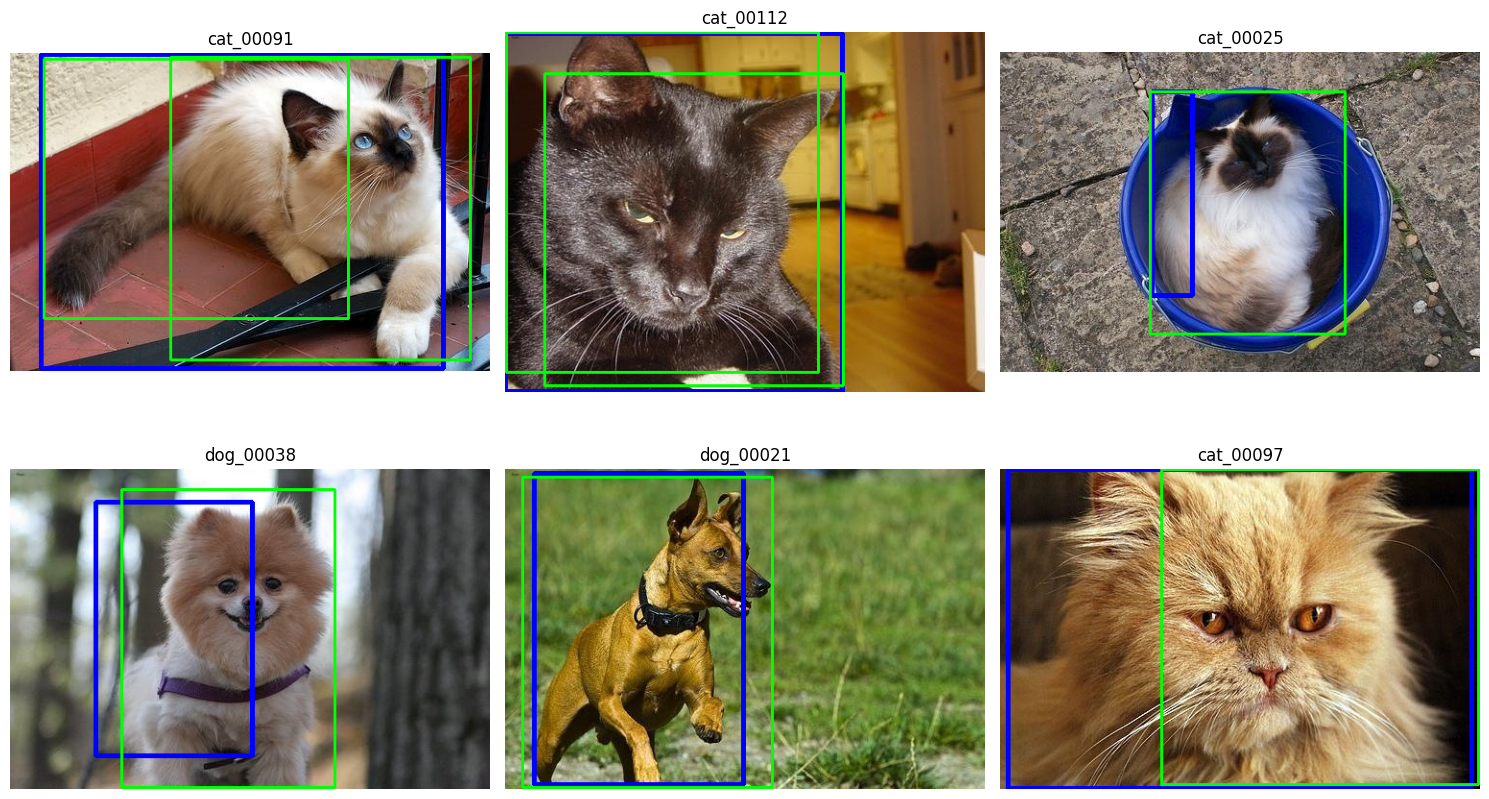

In [4]:
# Display a reproducible 6-image annotation audit.
audit_model = YOLO("yolov8s.pt")
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
rng_audit = np.random.default_rng(1378)
indices = rng_audit.choice(len(oxford_rows), size=min(6, len(oxford_rows)), replace=False)
for ax, i in zip(axes.flat, indices):
    sample = oxford_rows[int(i)]
    frame = cv2.imread(sample["image_path"])
    gt = list(map(int, sample["bbox"]))
    result = audit_model.predict(frame, classes=[15,16], conf=0.35,
                                 imgsz=960, verbose=False)[0]
    cv2.rectangle(frame, tuple(gt[:2]), tuple(gt[2:]), (255,0,0), 3)
    for b in result.boxes:
        x1,y1,x2,y2 = map(int,b.xyxy[0].cpu().tolist())
        cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
    ax.imshow(cv2.cvtColor(frame,cv2.COLOR_BGR2RGB))
    ax.set_title(sample["sample_id"])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. COCO pet scenes — Hugging Face ClassLabel mapping

Your executed notebook confirmed `detection-datasets/coco` has a `val` split and an 80-class `ClassLabel` with **cat=15, dog=16**. These are *contiguous indices*, not original COCO category IDs (17/18).

This loader reads the category mapping from the dataset schema and verifies bounding-box format using the provided object `area` field. It uses only pet-containing images, saves up to 50 locally, and refuses ambiguous box conventions.

**Provenance:** Verify the dataset card identifies `val` as COCO 2017 validation before reporting it as official COCO-2017 validation. If provenance cannot be confirmed, describe results as the Hugging Face COCO mirror validation split.


In [5]:
# COCO HF loader: derive class IDs from ClassLabel and verify box format.
%pip -q install "datasets>=3" "huggingface_hub>=0.25"

from datasets import load_dataset, get_dataset_split_names
from PIL import Image
import io, json
import numpy as np

COCO = DATA / "coco"
COCO.mkdir(parents=True, exist_ok=True)
MAX_COCO = 50
HF_COCO_ID = "detection-datasets/coco"
coco_rows = []

splits = get_dataset_split_names(HF_COCO_ID)
if "val" not in splits:
    raise RuntimeError(f"Expected 'val' split; found {splits}")
ds = load_dataset(HF_COCO_ID, split="val", streaming=True)

cat_feature = ds.features["objects"]["category"].feature
cat_id = cat_feature.str2int("cat")
dog_id = cat_feature.str2int("dog")
print("Category mapping:", {"cat": cat_id, "dog": dog_id})
assert cat_id != dog_id

def as_pil(item):
    if isinstance(item, Image.Image):
        return item.convert("RGB")
    if isinstance(item, dict) and isinstance(item.get("bytes"), bytes):
        return Image.open(io.BytesIO(item["bytes"])).convert("RGB")
    raise ValueError("Image cannot be decoded.")

def bbox_format(objects, width, height):
    """Infer XYWH versus XYXY from annotated area; fail on ambiguity."""
    candidates = []
    for b, a, cid in zip(objects["bbox"], objects["area"], objects["category"]):
        if int(cid) not in (cat_id, dog_id) or len(b) != 4 or a <= 0:
            continue
        x1, y1, u, v = map(float, b)
        area = float(a)
        # Segmentation area may be smaller than box area; use geometric plausibility too.
        xywh_ok = (u > 0 and v > 0 and 0 <= x1 < width and
                   0 <= y1 < height and x1 + u <= width + 1 and y1 + v <= height + 1)
        xyxy_ok = (u > x1 and v > y1 and u <= width + 1 and v <= height + 1)
        if xywh_ok and not xyxy_ok:
            candidates.append("xywh")
        elif xyxy_ok and not xywh_ok:
            candidates.append("xyxy")
        elif xywh_ok and xyxy_ok:
            # Area approximates box size, but may be segmentation area.
            wh = u * v
            xy = (u - x1) * (v - y1)
            if abs(wh-area) < abs(xy-area)*0.5:
                candidates.append("xywh")
            elif abs(xy-area) < abs(wh-area)*0.5:
                candidates.append("xyxy")
    if not candidates:
        return None
    if len(set(candidates)) != 1:
        return None
    return candidates[0]

# Probe annotated pet scenes before processing 50 images.
probe = []
for row in ds:
    objects = row["objects"]
    if any(int(cid) in (cat_id, dog_id) for cid in objects["category"]):
        probe.append(row)
    if len(probe) >= 12:
        break

votes = [bbox_format(r["objects"], r["width"], r["height"]) for r in probe]
print("Box-format votes:", votes)
votes = [v for v in votes if v is not None]
if len(votes) < 3 or len(set(votes)) != 1:
    raise RuntimeError("Bounding-box convention is not verified. Inspect dataset card and example boxes.")
FORMAT = votes[0]
print("Inferred box format:", FORMAT)
print("Review at least one sample image with the annotated box before reporting metrics.")

def extract_pet_boxes(row):
    objects = row["objects"]
    output = []
    for b, cid in zip(objects["bbox"], objects["category"]):
        cid = int(cid)
        if cid not in (cat_id, dog_id):
            continue
        x, y, a, b2 = map(float, b)
        if FORMAT == "xywh":
            x2, y2 = x+a, y+b2
        else:
            x2, y2 = a, b2
        if 0 <= x < x2 <= row["width"]+1 and 0 <= y < y2 <= row["height"]+1:
            output.append({"class": "cat" if cid == cat_id else "dog",
                           "bbox": [x, y, x2, y2]})
    return output

# Streaming dataset is re-iterable; avoid downloading unrelated images.
for row in ds:
    if len(coco_rows) >= MAX_COCO:
        break
    boxes = extract_pet_boxes(row)
    if not boxes:
        continue
    image = as_pil(row["image"])
    sample_id = str(row["image_id"])
    path = COCO / f"{sample_id}.jpg"
    image.save(path, quality=95)
    coco_rows.append({"sample_id": sample_id, "image_path": str(path), "objects": boxes})

print("COCO images:", len(coco_rows),
      "pet instances:", sum(len(r["objects"]) for r in coco_rows))
if len(coco_rows) < MAX_COCO:
    print("WARNING: Fewer than 50 usable pet-containing scenes were loaded.")
(DATA / "coco_manifest.json").write_text(json.dumps(coco_rows, indent=2))


README.md:   0%|          | 0.00/58.0 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

dataset_infos.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

Category mapping: {'cat': 15, 'dog': 16}
Box-format votes: [None, 'xyxy', 'xyxy', 'xyxy', 'xyxy', 'xyxy', None, 'xyxy', 'xyxy', 'xyxy', 'xyxy', 'xyxy']
Inferred box format: xyxy
Review at least one sample image with the annotated box before reporting metrics.
COCO images: 50 pet instances: 61


15155

### COCO annotation visual check

Inspect six samples: blue = ground truth, green = YOLO. Verify the boxes align with actual pets before accepting the metric report.

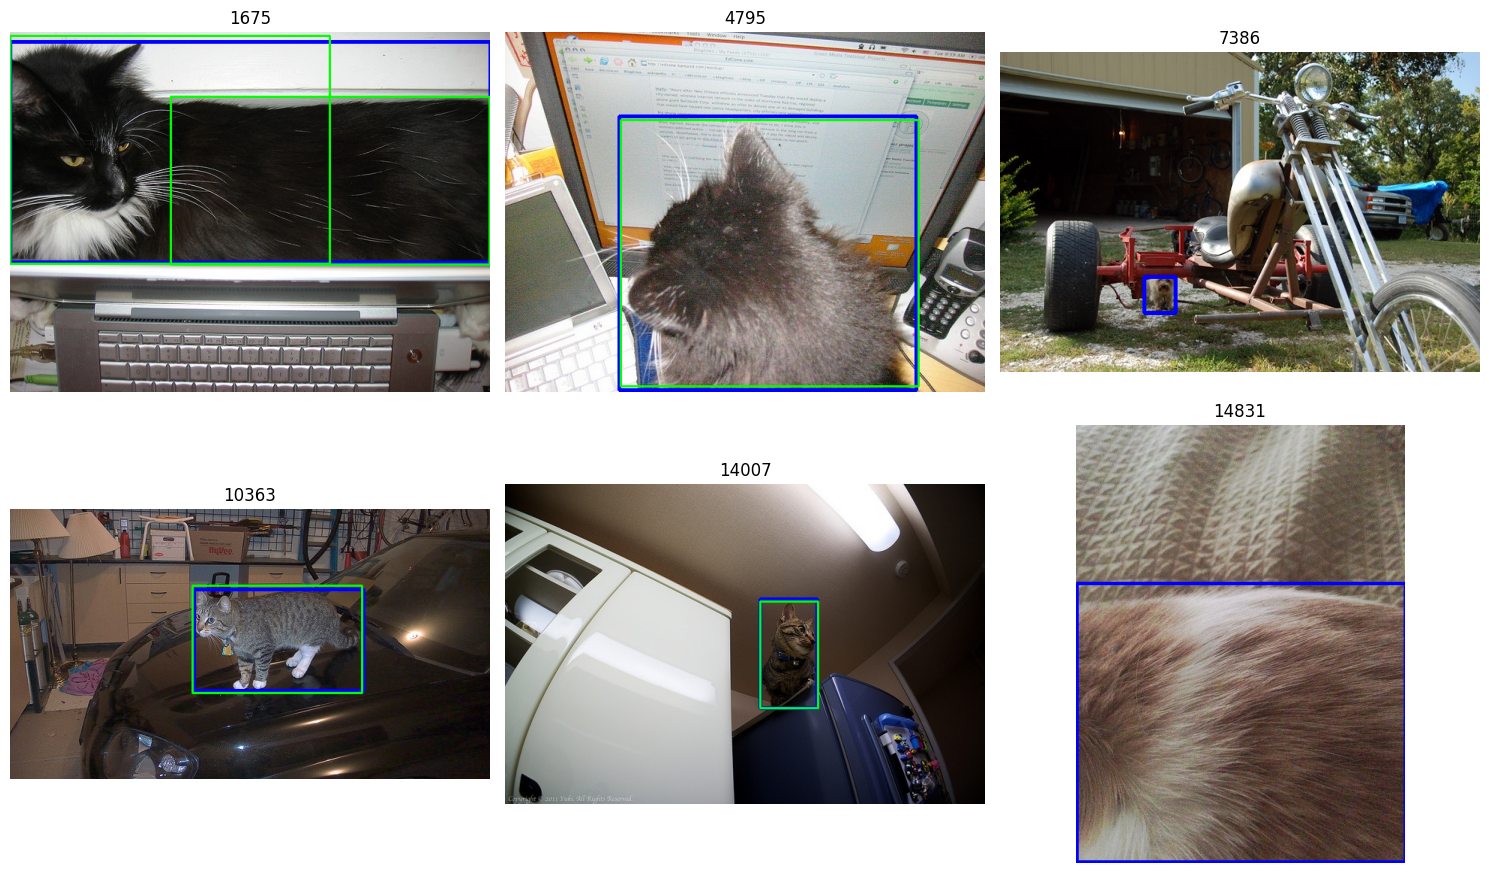

In [6]:
# Check the geometry of COCO boxes before evaluating.
if not coco_rows:
    print("No COCO samples to inspect.")
else:
    audit_detector = YOLO("yolov8s.pt")
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, sample in zip(axes.flat, coco_rows[:6]):
        image = cv2.imread(sample["image_path"])
        result = audit_detector.predict(image, classes=[15,16], conf=0.35,
                                        imgsz=960, verbose=False)[0]
        for gt in sample["objects"]:
            x1,y1,x2,y2 = map(int, gt["bbox"])
            cv2.rectangle(image,(x1,y1),(x2,y2),(255,0,0),3)
        for box in result.boxes:
            x1,y1,x2,y2 = map(int,box.xyxy[0].cpu().tolist())
            cv2.rectangle(image,(x1,y1),(x2,y2),(0,255,0),2)
        ax.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB))
        ax.set_title(sample["sample_id"])
        ax.axis("off")
    plt.tight_layout()
    plt.show()


### COCO official-annotation fallback (if you have downloaded files securely)

If you have the official `instances_val2017.json` and corresponding images, place them under `data/downloads/coco/annotations/` and `data/downloads/coco/`. Run the following cell to load up to 50 annotated pet scenes. This uses original COCO category IDs and XYWH annotation boxes.


In [7]:
# Optional: use verified official COCO files already present in Colab/Drive.
ann_file = COCO / "annotations" / "instances_val2017.json"
if ann_file.exists():
    ann = json.loads(ann_file.read_text())
    image_info = {int(i["id"]): i for i in ann["images"]}
    grouped = {}
    for a in ann["annotations"]:
        if a["category_id"] in (17,18) and not a.get("iscrowd", 0):
            grouped.setdefault(a["image_id"], []).append(a)
    existing_ids = {r["sample_id"] for r in coco_rows}
    for image_id in sorted(grouped):
        if len(coco_rows) >= MAX_COCO:
            break
        if str(image_id) in existing_ids:
            continue
        meta = image_info[image_id]
        path = COCO / meta["file_name"]
        if not path.exists() or cv2.imread(str(path)) is None:
            continue
        boxes = []
        for a in grouped[image_id]:
            x,y,w,h = a["bbox"]
            boxes.append({"class": "cat" if a["category_id"]==17 else "dog",
                          "bbox": [x,y,x+w,y+h]})
        coco_rows.append({"sample_id": str(image_id),
                          "image_path": str(path), "objects": boxes})
    print("Loaded official COCO samples:", len(coco_rows))
else:
    print("Official COCO annotation JSON not present; this optional cell was skipped.")


Official COCO annotation JSON not present; this optional cell was skipped.


## 4. Compare YOLOv8n and YOLOv8s on available, annotated images

This section always evaluates the 100 Oxford samples. It adds COCO **only if actual annotated images were loaded**. Each result includes the source dataset so Oxford-only results cannot be mistaken for the full planned 150-image comparison.

Use the same inference settings and IoU ≥0.5 matching for both models. These results are **evaluation**, not training.


In [8]:
oxford_samples = [
    {"sample_id": "oxford:"+r["sample_id"], "image_path": r["image_path"],
     "objects": [{"class": r["class"], "bbox": r["bbox"]}]} for r in oxford_rows
]
coco_samples = [
    {"sample_id": "coco:"+r["sample_id"], "image_path": r["image_path"],
     "objects": r["objects"]} for r in coco_rows
]
samples = oxford_samples + coco_samples
print(f"Actual evaluation set: Oxford={len(oxford_samples)}, COCO={len(coco_samples)}, total={len(samples)}")
rows = []
for model_name in ("yolov8n.pt", "yolov8s.pt"):
    detector = YOLO(model_name)
    for sample in samples:
        image = cv2.imread(sample["image_path"])
        if image is None:
            raise RuntimeError(f"Cannot read {sample['image_path']}")
        t0 = time.perf_counter()
        pred = detector.predict(image, classes=[15,16], conf=0.35,
                                imgsz=960, verbose=False)[0]
        elapsed_ms = (time.perf_counter()-t0)*1000
        boxes = [{"class": pred.names[int(b.cls[0])],
                  "bbox": b.xyxy[0].cpu().tolist(),
                  "confidence": float(b.conf[0])} for b in pred.boxes]
        matched = match_detections(sample["objects"], boxes, iou_threshold=0.5)
        rows.append({"model": model_name, "sample_id": sample["sample_id"],
                     "source": sample["sample_id"].split(":",1)[0],
                     **matched, "latency_ms": elapsed_ms})
    print("Completed:", model_name)
raw = pd.DataFrame(rows)
raw.to_csv(METRICS/"detection_per_image.csv", index=False)
summary = []
for (model_name, source), group in raw.groupby(["model", "source"]):
    m = detection_metrics(group.to_dict("records"))
    summary.append({"model": model_name, "source": source, "images": len(group), **m,
                    "mean_latency_ms": group["latency_ms"].mean(),
                    "p95_latency_ms": group["latency_ms"].quantile(.95)})
comparison = pd.DataFrame(summary)
comparison.to_csv(METRICS/"model_comparison.csv", index=False)
display(comparison)

print("Note: COCO results appear only if actual COCO images and annotations were loaded.")


Actual evaluation set: Oxford=100, COCO=50, total=150
Completed: yolov8n.pt
Completed: yolov8s.pt


,model,source,images,TP,FP,FN,pet_recall,pet_precision,mean_latency_ms,p95_latency_ms
0,yolov8n.pt,coco,50,45,8,16,0.737705,0.849057,343.124486,490.887012
1,yolov8n.pt,oxford,100,51,50,49,0.510000,0.504950,440.868066,934.065862
2,yolov8s.pt,coco,50,51,7,10,0.836066,0.879310,919.598095,1312.623013
3,yolov8s.pt,oxford,100,62,48,38,0.620000,0.563636,952.258166,1435.231091


Note: COCO results appear only if actual COCO images and annotations were loaded.


## 4A. Export evaluation results and dataset manifests

Run this cell **after the YOLO model-comparison cell**. It verifies that the metrics were generated, saves the Oxford/COCO sample manifests under `data/manifests/`, packages the entire manifest folder into one ZIP, and triggers three Colab downloads.

**Downloads:** `model_comparison.csv`, `detection_per_image.csv`, `petguard_data_manifests.zip`. The ZIP contains only JSON manifests (IDs, labels, bounding boxes, source metadata), **not** dataset images or model weights. The original manifests may contain Colab-specific absolute image paths; this export normalizes paths to repository-relative paths so the manifests are more portable. Re-download images before using those paths in a new session.

If a download prompt is blocked, allow multiple downloads in the browser, or rerun the individual `files.download(...)` calls.

In [9]:
# Export actual evaluation outputs; fail clearly if model evaluation was not run.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
import json

METRICS = REPO / "results" / "metrics"
MANIFESTS = REPO / "data" / "manifests"
MANIFESTS.mkdir(parents=True, exist_ok=True)

required_metrics = [
    METRICS / "model_comparison.csv",
    METRICS / "detection_per_image.csv",
]
missing = [str(p) for p in required_metrics if not p.is_file() or p.stat().st_size == 0]
if missing:
    raise FileNotFoundError(
        "Run the YOLO model-comparison cell first. Missing outputs: " + ", ".join(missing)
    )

# Keep dataset identity and bounding boxes; make local image paths repo-relative.
manifest_specs = [
    ("oxford_manifest.json", "oxford_rows"),
    ("coco_manifest.json", "coco_rows"),
]
for filename, variable_name in manifest_specs:
    if variable_name not in globals():
        raise RuntimeError(f"Run the dataset-loading cell first: {variable_name} is undefined")
    records = globals()[variable_name]
    if not isinstance(records, list) or not records:
        raise ValueError(f"No samples available for {filename}; cannot export an empty manifest")
    portable = []
    for record in records:
        item = dict(record)
        if "image_path" in item:
            image_path = Path(item["image_path"])
            try:
                item["image_path"] = image_path.relative_to(REPO).as_posix()
            except ValueError:
                # The original path remains in the source manifest; do not pretend it is portable.
                item["image_path"] = str(image_path)
        portable.append(item)
    (MANIFESTS / filename).write_text(json.dumps(portable, indent=2), encoding="utf-8")
    print(f"Saved {filename}: {len(portable)} samples")

zip_path = REPO / "petguard_data_manifests.zip"
with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for path in sorted(MANIFESTS.glob("*.json")):
        archive.write(path, arcname=f"data/manifests/{path.name}")

with ZipFile(zip_path) as archive:
    if archive.testzip() is not None:
        raise RuntimeError("Manifest ZIP integrity check failed")
    print("ZIP contents:", archive.namelist())

# Three browser downloads. If prompts are blocked, run each line separately.
for path in [*required_metrics, zip_path]:
    print("Downloading:", path.name, f"({path.stat().st_size:,} bytes)")
    files.download(str(path))


Saved oxford_manifest.json: 100 samples
Saved coco_manifest.json: 50 samples
ZIP contents: ['data/manifests/coco_manifest.json', 'data/manifests/oxford_manifest.json']
Downloading: model_comparison.csv (469 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: detection_per_image.csv (16,990 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: petguard_data_manifests.zip (3,882 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Optional helper — prepare a frame-labeling sheet from an existing Gradio run

Set `RUN_DIR` to one `results/runs/<run_id>` folder and run the cell. It samples up to 10 separated frames **per run** and exports a draft labeling CSV. Combine drafts from several independent videos to reach approximately 50 PetGuard-specific samples.

**Ground-truth labels remain blank on purpose.** Watch the original video and label SAFE/VIOLATION yourself. The predicted status comes from the system's temporally confirmed frame status. Do not evaluate the same clips used to tune your polygon or model threshold.


In [10]:
# Optional: prepare a review sheet; do not fabricate ground-truth labels.
RUN_DIR = None  # e.g., REPO/"results"/"runs"/"your_run_id"
if RUN_DIR is None:
    print("Set RUN_DIR to an actual Gradio run folder to create a draft labeling sheet.")
else:
    run_dir = Path(RUN_DIR)
    predictions = pd.read_csv(run_dir/"frame_predictions.csv")
    sample_count = min(10, len(predictions))
    indices = np.linspace(0, len(predictions)-1, sample_count, dtype=int)
    sampled = predictions.iloc[indices].copy()
    sampled["sample_id"] = [f"{run_dir.name}_frame_{int(f)}" for f in sampled["frame"]]
    sampled["source"] = "PetGuard video"
    sampled["video_id"] = run_dir.name
    sampled["frame_id"] = sampled["frame"]
    sampled["scenario"] = ""
    sampled["pet_count_ground_truth"] = pd.NA
    sampled["expected_zone_status"] = ""  # manually label before computing metrics
    sampled["predicted_zone_status"] = sampled["confirmed_violation"].map(
        {True:"VIOLATION", False:"SAFE"})
    sampled["zone_mode"] = json.loads((run_dir/"zone_config.json").read_text())["zone_mode"]
    sampled["notes"] = ""
    cols = ["sample_id","source","video_id","frame_id","scenario",
            "pet_count_ground_truth","expected_zone_status",
            "predicted_zone_status","zone_mode","notes"]
    draft = run_dir/"zone_labels_DRAFT.csv"
    sampled[cols].to_csv(draft, index=False)
    print("Draft created:", draft, "— ground truth must be filled manually.")


Set RUN_DIR to an actual Gradio run folder to create a draft labeling sheet.


## 5. PetGuard-specific zone evaluation — 50 independently labeled samples

Create `data/evaluation_labels.csv` using the provided template. Include source video and frame IDs, the confirmed zone used, ground-truth SAFE/VIOLATION, and the predicted SAFE/VIOLATION. To avoid leakage, label before looking at predictions and avoid treating adjacent near-identical frames as independent.

For **frame-level** evaluation, consistently use `candidate_violation` (raw zone decision) or `confirmed_violation` (temporally filtered status), and state which. A video alert is an event, not a frame-level label.

Human-only and empty-room frames should have expected status SAFE. Do not fabricate labels or fill the template with example counts.


In [11]:
LABELS = REPO/"data"/"evaluation_labels.csv"
if not LABELS.exists():
    print("Not evaluated yet. Create data/evaluation_labels.csv with verified labels.")
else:
    metrics = evaluate_zones(LABELS, METRICS/"zone_metrics.csv")
    display(pd.DataFrame([metrics]))
    matrix = np.array([[metrics["TN"],metrics["FP"]],
                       [metrics["FN"],metrics["TP"]]])
    fig, ax = plt.subplots(figsize=(5,4))
    ax.imshow(matrix, cmap="Blues")
    for (i,j), v in np.ndenumerate(matrix):
        ax.text(j, i, str(v), ha="center", va="center")
    ax.set_xticks([0,1], ["SAFE","VIOLATION"])
    ax.set_yticks([0,1], ["SAFE","VIOLATION"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title("PetGuard Zone Confusion Matrix")
    plt.tight_layout()
    plt.savefig(METRICS/"confusion_matrix.png", dpi=150)
    plt.show()


Not evaluated yet. Create data/evaluation_labels.csv with verified labels.


## 6. Report results vs Blueprint targets

- Pet detection recall target: ≥85%.
- Zone decision accuracy target: ≥90%.
- False violation rate target: ≤10%.
- Processing: report mean/P95 milliseconds per frame, and end-to-end FPS from actual Gradio runs.

**Caveats:** Oxford mask-derived boxes are approximations; COCO is a pretrained-model benchmark; 50 zone samples may be correlated if taken from the same video. Report these limitations honestly.

**Commit only:** notebook, code, small evaluation manifests/labels, CSV metrics, and plots. Avoid committing entire Oxford/COCO archives or unlicensed videos.
